# 1. Dataset Overview

This project explores a cross-linking mass spectrometry (XL-MS)
dataset from the Rappsilber Lab.

The initial analysis focuses on one CSM-level xiFDR result file
from the 26S proteasome dataset.

## Key terminology

- **Spectrum:** Experimental MS/MS measurement represented by m/z peaks
  and their intensities.
- **CSM (Crosslink Spectrum Match):** A proposed match between an
  experimental MS/MS spectrum and a crosslinked peptide pair.
- **FDR (False Discovery Rate):** The estimated proportion of false
  discoveries among accepted identifications.

# 2. Dataset Structure

The selected CSM-level table contains 1,035 rows and 59 columns.

Each row represents a Crosslink Spectrum Match (CSM).

The columns describe several aspects of the match:

- Experimental MS/MS spectrum
- Precursor mass and charge
- Matched peptides and proteins
- Crosslink positions and chemistry
- Fragment evidence
- Match score and confidence
- Target/decoy classification
- FDR estimates
- Peptide-pair, crosslink, and protein-interaction identifiers

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn

In [4]:
import pandas as pd

file = "data/26S/no-filter/B161103_06_Lumos_ML_IN_205_26SProt_BS3_Tryp_SECFr15.mgf_IDed_set_0_1_2.fasta.result.csv_boost_CSM_xiFDR2.2.betaB.csv"

df = pd.read_csv(file)

In [5]:
df.shape

(1035, 59)

In [28]:
df.head(5)

,PSMID,run,scan,PeakListFileName,ScanId,exp charge,exp m/z,exp mass,exp fractionalmass,match charge,...,Unnamed: 49,PeptidePairFDR,Protein1FDR,Protein2FDR,LinkFDR,PPIFDR,peptide pair id,link id,ppi id,info
0,Scan: 51364 Run: B161103_06_Lumos_ML_IN_205_26...,B161103_06_Lumos_ML_IN_205_26SProt_BS3_Tryp_SE...,51364,B161103_06_Lumos_ML_IN_205_26SProt_BS3_Tryp_SE...,35488,3,1132.260,3393.759,0.759,3,...,NaN,0.0,0.0,0.0,0.0,0.0,2599,473,219,NaN
1,Scan: 22619 Run: B161103_06_Lumos_ML_IN_205_26...,B161103_06_Lumos_ML_IN_205_26SProt_BS3_Tryp_SE...,22619,B161103_06_Lumos_ML_IN_205_26SProt_BS3_Tryp_SE...,9782,4,914.981,3655.895,0.895,4,...,NaN,0.0,0.0,0.0,0.0,0.0,2265,495,234,NaN
2,Scan: 64951 Run: B161103_06_Lumos_ML_IN_205_26...,B161103_06_Lumos_ML_IN_205_26SProt_BS3_Tryp_SE...,64951,B161103_06_Lumos_ML_IN_205_26SProt_BS3_Tryp_SE...,47680,4,1193.172,4768.659,0.659,4,...,NaN,0.0,0.0,0.0,0.0,0.0,12918,1151,3,NaN
3,Scan: 64948 Run: B161103_06_Lumos_ML_IN_205_26...,B161103_06_Lumos_ML_IN_205_26SProt_BS3_Tryp_SE...,64948,B161103_06_Lumos_ML_IN_205_26SProt_BS3_Tryp_SE...,47677,5,954.739,4768.657,0.657,5,...,NaN,0.0,0.0,0.0,0.0,0.0,12262,1128,3,NaN
4,Scan: 64514 Run: B161103_06_Lumos_ML_IN_205_26...,B161103_06_Lumos_ML_IN_205_26SProt_BS3_Tryp_SE...,64514,B161103_06_Lumos_ML_IN_205_26SProt_BS3_Tryp_SE...,47258,3,1330.341,3988.002,0.002,3,...,NaN,0.0,0.0,0.0,0.0,0.0,2745,477,219,NaN


In [15]:
df.info

<bound method DataFrame.info of                                                   PSMID  \
0     Scan: 51364 Run: B161103_06_Lumos_ML_IN_205_26...   
1     Scan: 22619 Run: B161103_06_Lumos_ML_IN_205_26...   
2     Scan: 64951 Run: B161103_06_Lumos_ML_IN_205_26...   
3     Scan: 64948 Run: B161103_06_Lumos_ML_IN_205_26...   
4     Scan: 64514 Run: B161103_06_Lumos_ML_IN_205_26...   
...                                                 ...   
1030  Scan: 9709 Run: B161103_06_Lumos_ML_IN_205_26S...   
1031  Scan: 17896 Run: B161103_06_Lumos_ML_IN_205_26...   
1032  Scan: 39721 Run: B161103_06_Lumos_ML_IN_205_26...   
1033  Scan: 42985 Run: B161103_06_Lumos_ML_IN_205_26...   
1034  Scan: 17260 Run: B161103_06_Lumos_ML_IN_205_26...   

                                                    run   scan  \
0     B161103_06_Lumos_ML_IN_205_26SProt_BS3_Tryp_SE...  51364   
1     B161103_06_Lumos_ML_IN_205_26SProt_BS3_Tryp_SE...  22619   
2     B161103_06_Lumos_ML_IN_205_26SProt_BS3_Tryp_SE...  6495

In [16]:
df.isna().all()

PSMID                     False
run                       False
scan                      False
PeakListFileName          False
ScanId                    False
exp charge                False
exp m/z                   False
exp mass                  False
exp fractionalmass        False
match charge              False
match mass                False
match fractionalmass      False
Protein1                  False
Name1                     False
Description1              False
Decoy1                    False
Protein2                  False
Name2                     False
Description2              False
Decoy2                    False
PepSeq1                   False
PepSeq2                   False
PepPos1                   False
PepPos2                   False
PeptideLength1            False
PeptideLength2            False
LinkPos1                  False
LinkPos2                  False
ProteinLinkPos1           False
ProteinLinkPos2           False
Charge                    False
Crosslin

In [17]:
df.isna().sum().sort_values(ascending=False).head(15)

info                    1035
Unnamed: 49             1035
Name1                   1021
Protein1FDR               56
Protein2FDR               51
exp charge                 0
exp m/z                    0
PeakListFileName           0
ScanId                     0
run                        0
PSMID                      0
match mass                 0
match fractionalmass       0
Protein1                   0
Description1               0
dtype: int64

In [24]:
df['Name1'].isna().sum(), df['Name1'].notna().sum()

(np.int64(1021), np.int64(14))

In [25]:
df['Protein1FDR'].isna().sum(), df['Protein1FDR'].notna().sum()

(np.int64(56), np.int64(979))

In [26]:
df['Protein2FDR'].isna().sum(), df['Protein2FDR'].notna().sum()

(np.int64(51), np.int64(984))

## Missing Values

The two columns `info` and `Unnamed: 49` are completely empty in this
file.

A number of values are missing from `Protein1FDR` and `Protein2FDR`. Also, `Name1` is mostly NaN. These fields will be investigated further to understand the reason for the missing values before making any changes.

No missing values were found in the main experimental fields such as
spectrum identifiers, mass/charge measurements, protein identifiers,
and match information.

In [18]:
df[df['Protein1FDR'].isna()][
    ['Protein1', 'Protein2', 'isDecoy', 'isTT', 'isTD', 'isDD',
     'Score', 'fdr', 'Protein1FDR', 'Protein2FDR']
].head(10)

,Protein1,Protein2,isDecoy,isTT,isTD,isDD,Score,fdr,Protein1FDR,Protein2FDR
81,P07281,P07281,False,True,False,False,14.236,0.000,NaN,NaN
210,P38764,decoy:Q04062,True,False,True,False,12.412,0.019,NaN,NaN
223,P00359,P00360;P00358;P00359,False,True,False,False,12.240,0.000,NaN,NaN
224,P07281,P07281,False,True,False,False,12.220,0.000,NaN,NaN
294,P38348,P38348,False,True,False,False,11.369,0.000,NaN,NaN
336,P32379,P23724,False,True,False,False,10.901,0.042,NaN,NaN
351,P0CX54,decoy:P0CX54,True,False,True,False,10.703,0.002,NaN,NaN
369,P48164,P48164;P26786,False,True,False,False,10.607,0.002,NaN,NaN
373,P23724,P30656,False,True,False,False,10.568,0.062,NaN,0.0
375,P26786,P48164;P26786,False,True,False,False,10.532,0.002,NaN,NaN


### Missing Protein-Level FDR Values

Missing values in `Protein1FDR` and `Protein2FDR` do not appear to indicate missing CSMs. The affected rows can still contain vali dprotein identifiers, scores, and spectrum-level FDR values.

Therefore, these values will be preserved as missing rather than imputed during the initial EDA.

In [19]:
df[df['Name1'].isna()][
    ['Protein1', 'Protein2', 'Name1', 'Name2', 'isDecoy', 'Score', 'fdr']
]

,Protein1,Protein2,Name1,Name2,isDecoy,Score,fdr
0,Q04062,Q04062,NaN,Q04062,False,21.327,0.000
1,P43593,P43593,NaN,P43593,False,21.264,0.000
2,P33297,P53549,NaN,P53549,False,20.832,0.000
3,P53549,P33297,NaN,P33297,False,19.865,0.000
4,Q04062,Q04062,NaN,Q04062,False,18.755,0.000
...,...,...,...,...,...,...,...
1029,P09938,P09938,NaN,P09938,False,1.842,0.009
1030,P0CS90,P0CS90,NaN,P0CS90,False,1.741,0.009
1031,P50086,P50086,NaN,P50086,False,1.481,0.009
1032,P33297,P33297,NaN,P33297,False,1.478,0.009


In [23]:
df[['Protein1', 'Protein2', 'PepSeq1', 'PepSeq2',
    'Score', 'fdr', 'LinkFDR', 'PPIFDR']].head()

,Protein1,Protein2,PepSeq1,PepSeq2,Score,fdr,LinkFDR,PPIFDR
0,Q04062,Q04062,MFNNHEIDTILSTLR,FYDKINQLSVVK,21.327,0.0,0.0,0.0
1,P43593,P43593,HSGKVYPITLSTDATSADLK,SKAEELTQVPSAR,21.264,0.0,0.0,0.0
2,P33297,P53549,LAAPQLVQMYIGEGAKLVR,TLLAKAVAATIGANFIFSPASGIVDK,20.832,0.0,0.0,0.0
3,P53549,P33297,TLLAKAVAATIGANFIFSPASGIVDK,LAAPQLVQMYIGEGAKLVR,19.865,0.0,0.0,0.0
4,Q04062,Q04062,FYEEKLWFQLSESLTK,MFNNHEIDTILSTLR,18.755,0.0,0.0,0.0


In [8]:
df.columns.tolist()

['PSMID',
 'run',
 'scan',
 'PeakListFileName',
 'ScanId',
 'exp charge',
 'exp m/z',
 'exp mass',
 'exp fractionalmass',
 'match charge',
 'match mass',
 'match fractionalmass',
 'Protein1',
 'Name1',
 'Description1',
 'Decoy1',
 'Protein2',
 'Name2',
 'Description2',
 'Decoy2',
 'PepSeq1',
 'PepSeq2',
 'PepPos1',
 'PepPos2',
 'PeptideLength1',
 'PeptideLength2',
 'LinkPos1',
 'LinkPos2',
 'ProteinLinkPos1',
 'ProteinLinkPos2',
 'Charge',
 'Crosslinker',
 'CrosslinkerModMass',
 'MinFragments',
 'P1Fragments',
 'P2Fragments',
 'PeptidesWithDoublets',
 'PeptidesWithStubs',
 'minPepCoverage',
 'minPepCoverageAbsolute',
 'Score',
 'isDecoy',
 'isTT',
 'isTD',
 'isDD',
 'fdrGroup',
 'fdr',
 'ifdr',
 'PEP',
 'Unnamed: 49',
 'PeptidePairFDR',
 'Protein1FDR',
 'Protein2FDR',
 'LinkFDR',
 'PPIFDR',
 'peptide pair id',
 'link id',
 'ppi id',
 'info']

In [10]:
df.dtypes

PSMID                         str
run                           str
scan                        int64
PeakListFileName              str
ScanId                      int64
exp charge                  int64
exp m/z                   float64
exp mass                  float64
exp fractionalmass        float64
match charge                int64
match mass                float64
match fractionalmass      float64
Protein1                      str
Name1                         str
Description1                  str
Decoy1                       bool
Protein2                      str
Name2                         str
Description2                  str
Decoy2                       bool
PepSeq1                       str
PepSeq2                       str
PepPos1                       str
PepPos2                       str
PeptideLength1              int64
PeptideLength2              int64
LinkPos1                    int64
LinkPos2                    int64
ProteinLinkPos1               str
ProteinLinkPos

In [12]:
df[['Score', 'fdr', 'ifdr', 'PEP',
    'PeptidePairFDR', 'LinkFDR', 'PPIFDR']].describe()

,Score,fdr,ifdr,PEP,PeptidePairFDR,LinkFDR,PPIFDR
count,1035.000000,1035.000000,1035.000000,1035.000000,1035.00000,1035.000000,1035.000000
mean,9.455119,0.083397,0.084986,0.168540,0.05507,0.003948,0.003859
std,3.414187,0.173977,0.173483,0.284754,0.13857,0.009002,0.016328
min,0.530000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000
25%,7.058000,0.000000,0.002000,0.003000,0.00000,0.000000,0.000000
50%,9.354000,0.002000,0.004000,0.007000,0.00300,0.000000,0.000000
75%,11.720500,0.037000,0.041000,0.226000,0.00600,0.003000,0.000000
max,21.327000,0.825000,0.825000,1.030000,0.81500,0.046000,0.127000


In [13]:
df[['isDecoy', 'isTT', 'isTD', 'isDD', 'fdrGroup']].value_counts()

isDecoy  isTT   isTD   isDD   fdrGroup    
False    True   False  False  Self > 4        634
                              Between > 4     383
True     False  True   False  Between > 4       9
                              Self > 4          7
                False  True   Self > 4          2
Name: count, dtype: int64

## Data Types

The dataset contains several types of fields:

- **Numerical:** masses, charges, scores, fragment counts, peptide lengths, and FDR values.
- **Boolean:** target/decoy indicators such as `isDecoy`, `isTT`, `isTD`, and `isDD`.
- **Text/string:** protein identifiers, peptide sequences, spectrum identifiers, and categorical metadata.
- **Identifiers:** `peptide pair id`, `link id`, and `ppi id`.
- **Empty columns:** `info` and `Unnamed: 49`.

The data types are generally consistent with the apparent role of each field.

In [31]:
df[['Charge', 'Crosslinker']].value_counts().sort_index()

Charge  Crosslinker
3       BS3            168
4       BS3            473
5       BS3            310
6       BS3             72
7       BS3              9
8       BS3              3
Name: count, dtype: int64

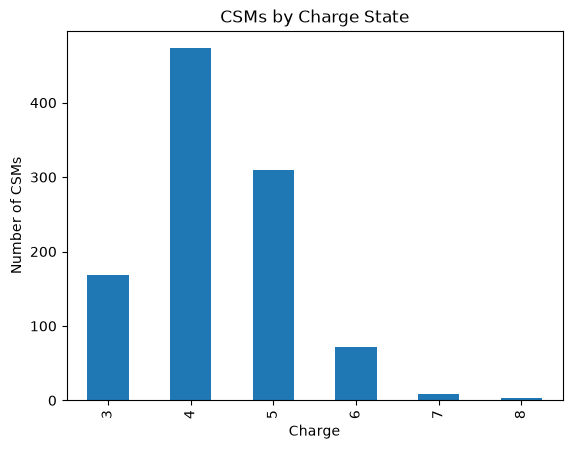

In [34]:
df['Charge'].value_counts().sort_index().plot(kind='bar')

plt.xlabel('Charge')
plt.ylabel('Number of CSMs')
plt.title('CSMs by Charge State')
plt.show()

In [35]:
df[['PeptideLength1', 'PeptideLength2']].describe()

,PeptideLength1,PeptideLength2
count,1035.000000,1035.000000
mean,20.822222,13.422222
std,6.572118,4.900409
min,8.000000,6.000000
25%,16.000000,10.000000
50%,20.000000,12.000000
75%,24.000000,16.000000
max,46.000000,44.000000


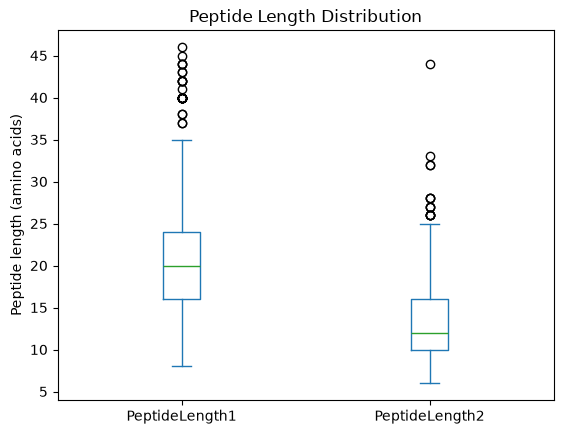

In [36]:
df[['PeptideLength1', 'PeptideLength2']].plot(
    kind='box',
    ylabel='Peptide length (amino acids)',
    title='Peptide Length Distribution'
)

plt.show()

In [37]:
df[['MinFragments',
    'P1Fragments',
    'P2Fragments',
    'minPepCoverage',
    'minPepCoverageAbsolute']].describe()

,MinFragments,P1Fragments,P2Fragments,minPepCoverage,minPepCoverageAbsolute
count,1035.000000,1035.000000,1035.000000,1035.000000,1035.000000
mean,7.511111,14.273430,7.561353,0.311223,7.511111
std,3.338803,5.619772,3.378286,0.114572,3.338803
min,2.000000,2.000000,2.000000,0.062000,2.000000
25%,5.000000,10.000000,5.000000,0.233000,5.000000
50%,7.000000,14.000000,7.000000,0.300000,7.000000
75%,10.000000,18.000000,10.000000,0.391000,10.000000
max,23.000000,37.000000,23.000000,0.750000,23.000000


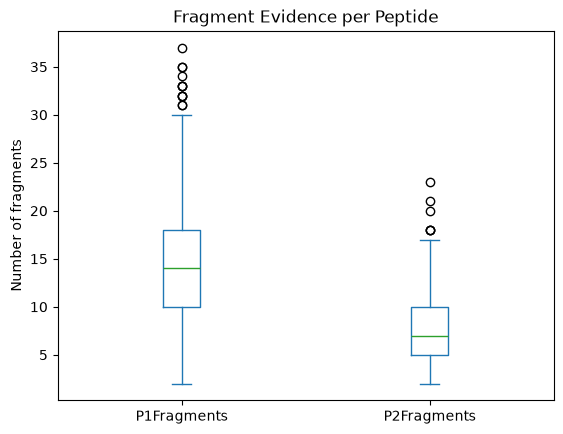

In [38]:
df[['P1Fragments', 'P2Fragments']].plot(
    kind='box',
    ylabel='Number of fragments',
    title='Fragment Evidence per Peptide'
)

plt.show()

In [39]:
df[['PeptideLength1', 'P1Fragments',
    'PeptideLength2', 'P2Fragments']].corr()

,PeptideLength1,P1Fragments,PeptideLength2,P2Fragments
PeptideLength1,1.000000,0.509205,-0.221324,0.001319
P1Fragments,0.509205,1.000000,-0.195027,0.312069
PeptideLength2,-0.221324,-0.195027,1.000000,0.428365
P2Fragments,0.001319,0.312069,0.428365,1.000000
